# Interactive Floor Plan Extractor (Local MLX & OpenRouter API)

Choose any floor plan and extract its booths, walls, doors and every other layout element into structured JSON via either:
1. **Local MLX models** running on-device on Apple Silicon (offline, private, zero cost).
2. **OpenRouter API** calling cloud vision models.

The plan is cut into overlapping full-resolution tiles and each tile is sent to the model on its own. One request for the whole plan runs out of tokens after a few dozen items and shrinks the booth labels below what the vision encoder can read. Tile results are mapped back to plan pixels and merged, keeping one reading per booth ID.

### Kernel Note
The kernel `Python (floor-plan-vlm-bench)` is registered for local MLX inference. If running in another kernel, the notebook automatically routes local inference through `/Users/arya/miniconda3/envs/floor-plan-vlm-bench/bin/python`.


In [30]:
import os
from pathlib import Path

# ======================================================================
# 1. CONFIGURATION: PLAN & BACKEND ROUTE
# ======================================================================
PLAN = "plan1"  # Options: 'plan1', 'plan2', 'plan3', 'plan4', 'plan5', 'plan6'

# BACKEND ROUTE: 'local' (Apple Silicon MLX) or 'openrouter' (Cloud API)
BACKEND = "openrouter"  # 'local' or 'openrouter'

# IF BACKEND == 'local':
MODEL_ID = "mlx-community/Qwen3.5-9B-MLX-4bit"
# Local Options:
#   'mlx-community/Qwen3.5-4B-MLX-4bit'
#   'mlx-community/Qwen3.5-9B-MLX-4bit'
#   'mlx-community/Qwen3-VL-8B-Instruct-4bit'
#   'mlx-community/InternVL3-8B-MLX-4bit'
#   'mlx-community/gemma-4-e4b-it-4bit'
#   'mlx-community/gemma-4-12B-it-qat-4bit'
#   'mlx-community/gemma-3-27b-it-qat-4bit'

# IF BACKEND == 'openrouter':
OPENROUTER_MODEL = "openai/gpt-5.4-nano"
# OpenRouter Options:
#   'qwen/qwen-2.5-vl-72b-instruct'
#   'google/gemini-2.5-flash'
#   'anthropic/claude-3.5-sonnet'
#   'openai/gpt-4o'
OPENROUTER_API_KEY = os.environ.get("OPENROUTER_API_KEY", "")

MAX_TOKENS = 4096          # max tokens per tile response (reasoning models spend part of this thinking)
TILE_SIZE = 1000           # side in px of each crop sent to the model; plans smaller than this go as one tile
TILE_OVERLAP = 150         # px shared by neighbouring tiles so a booth cut by one tile edge is whole in the next
MAX_WORKERS = 4            # parallel tile requests (openrouter only; local runs tiles one by one)
# ======================================================================

ROOT = Path("..") if Path("..").resolve().name == "legend-only" else Path(".")
DATA_DIR = ROOT / "data"
PLAN_DIR = DATA_DIR / PLAN
IMAGE_PATH = PLAN_DIR / "layout.png"
TRUTH_PATH = PLAN_DIR / "truth.json"

print(f"Selected Plan   : {PLAN} ({IMAGE_PATH})")
print(f"Selected Backend: {BACKEND}")
if BACKEND == 'local':
    print(f"Selected Model  : {MODEL_ID}")
else:
    print(f"Selected Model  : {OPENROUTER_MODEL} via OpenRouter API")
    print(f"API Key Configured: {'Yes' if OPENROUTER_API_KEY else 'No (set OPENROUTER_API_KEY)'}")
print(f"Truth Exists    : {TRUTH_PATH.exists()}")

Selected Plan   : plan1 (../data/plan1/layout.png)
Selected Backend: openrouter
Selected Model  : openai/gpt-5.4-nano via OpenRouter API
API Key Configured: Yes
Truth Exists    : True


In [31]:
import base64
import json
import math
import os
import re
import subprocess
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

SYSTEM_PROMPT = """You read trade-show floor plans and return every layout element as JSON. You get one crop of a larger plan.

A booth is a filled rectangle with a printed label inside. The label is one or two capital letters followed by a number, such as A9, H18, F1, X3 or XX2. The fill colour shows the booth group, but the label is the only source for the ID.

Booth rules:
- Return one item per booth whose label you can read. Copy the label character for character.
- Letters and digits that look alike (1 and I, 0 and O, 5 and S, 8 and B) are the usual mistakes. Check the booths next to it: numbers in a row normally run in sequence, and every booth in a colour group shares one letter.
- Never invent a label to fill a gap in a sequence. If a booth is clearly there but its label is unreadable, return it with "id": null.
- "box" is the whole filled rectangle, not just the text. Use integers [x1, y1, x2, y2] from 0 to 1000, relative to this crop, origin at the top left, x to the right, y downward.

Other elements have "id": null. Classes:
- "booth": normal booth. "large_booth": the big X and XX booths, which carry an ID too.
- "stage": the grey stage and its extension.
- "blocked": solid black rectangles.
- "decor": white boxes marked DECOR.
- "wall": every wall line, one item per straight segment. Double lines are one wall.
- "door": door and gate symbols, including swing arcs and emergency exits.
- "pillar": small squares on or beside the walls.
- "table": a single table with its chairs.
- "seating": a block of table-and-chair groups. Box the block, not each table, when the groups sit in a tight grid.
- "audience": the grid of small circles in front of the stage.
- "stairs": stair symbols.
- "entrance" and "exit": the ENTRANCE area and EXIT signs.
- "object": anything else drawn on the plan that fits no class above.

General rules:
- Cover the whole crop. Do not stop after the booths; walls, doors, pillars and furniture count as much.
- Box every element tightly. A wall box is thin: a few units wide for a long wall.
- An element cut off by the crop edge still counts. End its box at the crop edge.
- Skip pure text such as dimensions, but keep the sign or box it sits in.
- List each element once, row by row from top to bottom, left to right within a row.
- Reply with JSON only, no commentary. If the crop holds nothing reply {"items":[]}.

Format: {"items":[{"class":"booth","id":"H1","box":[x1,y1,x2,y2]},{"class":"wall","id":null,"box":[x1,y1,x2,y2]}]}"""

USER_PROMPT = "Extract every element in this crop: booths first, then walls, doors, pillars, furniture and the rest."

BENCH_PYTHON = Path("/Users/arya/miniconda3/envs/floor-plan-vlm-bench/bin/python")
BOOTH_ID = re.compile(r"^[A-Z]{1,2}\d{1,3}$")

def clean_thinking(text: str) -> str:
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL)
    text = re.sub(r"<\|channel\|>thought.*?<channel\|>", "", text, flags=re.DOTALL)
    text = re.sub(r"<\|channel>thought.*?<channel\|>", "", text, flags=re.DOTALL)
    return text.strip()

def parse_or_salvage_items(raw_text: str) -> tuple[bool, list[dict]]:
    s = clean_thinking(raw_text)
    m = re.search(r"```(?:json)?\s*(\{.*\})\s*```", s, flags=re.DOTALL)
    candidate = m.group(1) if m else s
    start, end = candidate.find("{"), candidate.rfind("}")
    if start != -1 and end != -1 and end > start:
        try:
            obj = json.loads(candidate[start : end + 1])
            if isinstance(obj, dict):
                items = obj.get("items") or obj.get("booths") or obj.get("elements") or []
                if isinstance(items, list):
                    return True, [it for it in items if isinstance(it, dict)]
            elif isinstance(obj, list):
                return True, [it for it in obj if isinstance(it, dict)]
        except Exception:
            pass

    salvaged = []
    for match in re.finditer(r"\{[^{}]*\}", s):
        try:
            it = json.loads(match.group(0))
            if isinstance(it, dict) and any(k in it for k in ("box", "bbox", "bbox_2d", "id", "class")):
                salvaged.append(it)
        except Exception:
            continue
    return False, salvaged

def run_openrouter_api(image_path: str, model_name: str, api_key: str, system: str, prompt: str, max_tokens: int) -> tuple[float, str, str]:
    if not api_key:
        raise ValueError("OPENROUTER_API_KEY is not set. Set it in cell 1 or export OPENROUTER_API_KEY in your environment.")
    with open(image_path, "rb") as f:
        b64_img = base64.b64encode(f.read()).decode("utf-8")

    payload = {
        "model": model_name,
        "messages": [
            {"role": "system", "content": system},
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{b64_img}"}}
                ]
            }
        ],
        "temperature": 0.0,
        "max_tokens": max_tokens
    }
    req = urllib.request.Request(
        "https://openrouter.ai/api/v1/chat/completions",
        data=json.dumps(payload).encode("utf-8"),
        headers={
            "Authorization": f"Bearer {api_key}",
            "Content-Type": "application/json",
            "HTTP-Referer": "https://github.com/floor-plan-extractor",
            "X-Title": "Floor Plan Extractor"
        }
    )
    t0 = time.time()
    with urllib.request.urlopen(req, timeout=180) as resp:
        res_body = json.loads(resp.read().decode("utf-8"))
    elapsed = time.time() - t0
    choice = res_body["choices"][0]
    return elapsed, choice["message"].get("content") or "", choice.get("finish_reason") or ""

def run_local_mlx_model(model_id: str, image_paths: list[str], system: str, prompt: str, max_tokens: int) -> list[tuple[float, float, str]]:
    # mlx_vlm's chat template takes one prompt string, so the system text is prepended to it.
    full_prompt = f"{system}\n\n{prompt}"
    # The model is loaded once and reused for every tile.
    try:
        import mlx.core as mx
        from mlx_vlm import load, generate
        from mlx_vlm.prompt_utils import apply_chat_template
        from mlx_vlm.utils import load_config

        config = load_config(model_id)
        model, processor = load(model_id)
        formatted = apply_chat_template(processor, config, full_prompt, num_images=1, enable_thinking=False)
        out = []
        for path in image_paths:
            tg0 = time.time()
            res = generate(model, processor, formatted, image=[path], temperature=0.0, max_tokens=max_tokens, verbose=False)
            out.append((time.time() - tg0, getattr(res, "generation_tps", 0.0), res.text))
        return out
    except ImportError:
        # Fallback to invoking the floor-plan-vlm-bench conda environment
        if not BENCH_PYTHON.exists():
            raise RuntimeError(f"MLX is not installed in current kernel and {BENCH_PYTHON} not found.")
        code = f"""
import json, time
from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template
from mlx_vlm.utils import load_config

config = load_config({repr(model_id)})
model, processor = load({repr(model_id)})
formatted = apply_chat_template(processor, config, {repr(full_prompt)}, num_images=1, enable_thinking=False)
out = []
for path in {repr(list(image_paths))}:
    tg0 = time.time()
    res = generate(model, processor, formatted, image=[path], temperature=0.0, max_tokens={max_tokens}, verbose=False)
    out.append([time.time() - tg0, getattr(res, 'generation_tps', 0.0), res.text])
print('___OUTPUT_JSON___' + json.dumps(out))
"""
        proc = subprocess.run([str(BENCH_PYTHON), "-c", code], capture_output=True, text=True, check=True)
        for line in reversed(proc.stdout.splitlines()):
            if line.startswith("___OUTPUT_JSON___"):
                return [tuple(r) for r in json.loads(line[len("___OUTPUT_JSON___"):])]
        raise RuntimeError(f"Could not parse MLX output:\n{proc.stdout}\n{proc.stderr}")

def tile_starts(length: int, tile: int, overlap: int) -> list[int]:
    if length <= tile:
        return [0]
    n = math.ceil((length - overlap) / (tile - overlap))
    return [round(i * (length - tile) / (n - 1)) for i in range(n)]

def clean_id(value) -> str | None:
    if value in (None, "", "null", "None"):
        return None
    s = str(value).strip().upper().replace(" ", "")
    return s if BOOTH_ID.match(s) else None

def tile_item_to_plan(item: dict, tile: dict) -> dict | None:
    """Maps one tile-local 0-1000 item to plan pixels. margin is the distance to the nearest tile edge, negative if the box leaves the tile."""
    bb = item.get("box") or item.get("bbox_2d") or item.get("box_2d") or item.get("bbox")
    try:
        x1, y1, x2, y2 = [float(v) for v in bb]
    except Exception:
        return None
    if x2 <= x1 or y2 <= y1:
        return None
    margin = min(x1, y1, 1000 - x2, 1000 - y2)
    x1, x2 = max(0.0, x1), min(1000.0, x2)
    y1, y2 = max(0.0, y1), min(1000.0, y2)
    sx, sy = tile["w"] / 1000.0, tile["h"] / 1000.0
    return {
        "class": str(item.get("class", "booth")).lower(),
        "id": clean_id(item.get("id")),
        "box": [round(tile["x0"] + x1 * sx), round(tile["y0"] + y1 * sy), round(tile["x0"] + x2 * sx), round(tile["y0"] + y2 * sy)],
        "margin": margin,
    }

def merge_tile_items(items: list[dict], overlap_iou: float = 0.6) -> list[dict]:
    """One reading per booth. A booth seen in two tiles is kept from the tile where it sits furthest from the edge, since that reading is the least likely to be cut off."""
    kept, seen_ids = [], set()
    for it in sorted(items, key=lambda i: -i["margin"]):
        if it["id"] and it["id"] in seen_ids:
            continue
        if any(iou(xyxy_to_xywh(it["box"]), xyxy_to_xywh(k["box"])) >= overlap_iou for k in kept):
            continue
        if it["id"]:
            seen_ids.add(it["id"])
        kept.append(it)
    return kept

def xyxy_to_xywh(b):
    return [b[0], b[1], b[2] - b[0], b[3] - b[1]]

def iou(a, b):
    ix = max(0.0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union if union > 0 else 0.0

def convert_box(bb, mode, orig_w, orig_h, res_w, res_h):
    if not isinstance(bb, list) or len(bb) != 4:
        return [0.0, 0.0, 0.0, 0.0]
    try:
        v = [float(x) for x in bb]
    except Exception:
        return [0.0, 0.0, 0.0, 0.0]
    if mode == "rel1000_xyxy":
        x1, y1, x2, y2 = v[0] * orig_w / 1000.0, v[1] * orig_h / 1000.0, v[2] * orig_w / 1000.0, v[3] * orig_h / 1000.0
    elif mode == "rel1000_yxyx":
        y1, x1, y2, x2 = v[0] * orig_h / 1000.0, v[1] * orig_w / 1000.0, v[2] * orig_h / 1000.0, v[3] * orig_w / 1000.0
    elif mode == "res_px_xyxy":
        x1, y1, x2, y2 = v[0] * orig_w / res_w, v[1] * orig_h / res_h, v[2] * orig_w / res_w, v[3] * orig_h / res_h
    elif mode == "orig_px_xyxy":
        x1, y1, x2, y2 = v[0], v[1], v[2], v[3]
    else:
        x1, y1, w, h = v[0] * orig_w / 1000.0, v[1] * orig_h / 1000.0, v[2] * orig_w / 1000.0, v[3] * orig_h / 1000.0
        return [x1, y1, max(0.0, w), max(0.0, h)]
    return [x1, y1, max(0.0, x2 - x1), max(0.0, y2 - y1)]

In [32]:
# Cut the plan into overlapping tiles at native resolution
img_bgr = cv2.imread(str(IMAGE_PATH))
orig_h, orig_w = img_bgr.shape[:2]

tiles = []
for y0 in tile_starts(orig_h, TILE_SIZE, TILE_OVERLAP):
    for x0 in tile_starts(orig_w, TILE_SIZE, TILE_OVERLAP):
        crop = img_bgr[y0 : y0 + TILE_SIZE, x0 : x0 + TILE_SIZE]
        path = f"/tmp/interactive_vlm_{PLAN}_{len(tiles)}.png"
        cv2.imwrite(path, crop)
        tiles.append({"path": path, "x0": x0, "y0": y0, "w": crop.shape[1], "h": crop.shape[0]})

print(f"Original Image: {orig_w} x {orig_h} px")
print(f"Tiles         : {len(tiles)} of up to {TILE_SIZE} px with {TILE_OVERLAP} px overlap")

Original Image: 2349 x 2871 px
Tiles         : 12 of up to 1000 px with 150 px overlap


In [33]:
# Extract booths tile by tile, then map back to plan pixels and merge
def read_tile_openrouter(tile):
    api_key = OPENROUTER_API_KEY or os.environ.get("OPENROUTER_API_KEY", "")
    return run_openrouter_api(tile["path"], OPENROUTER_MODEL, api_key, SYSTEM_PROMPT, USER_PROMPT, MAX_TOKENS)

t_start = time.time()
if BACKEND == "openrouter":
    print(f"Routing {len(tiles)} tiles to OpenRouter API ({OPENROUTER_MODEL})...")
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        replies = list(pool.map(read_tile_openrouter, tiles))
else:
    print(f"Running local MLX inference on {len(tiles)} tiles using {MODEL_ID}...")
    local = run_local_mlx_model(MODEL_ID, [t["path"] for t in tiles], SYSTEM_PROMPT, USER_PROMPT, MAX_TOKENS)
    replies = [(gen_s, text, "") for gen_s, tps, text in local]
wall_s = time.time() - t_start

plan_items, truncated, raw_heads = [], 0, []
for n, (tile, (gen_s, raw_text, finish)) in enumerate(zip(tiles, replies)):
    strict_ok, tile_items = parse_or_salvage_items(raw_text)
    mapped = [m for m in (tile_item_to_plan(it, tile) for it in tile_items) if m]
    plan_items.extend(mapped)
    truncated += finish == "length" or not strict_ok
    raw_heads.append(raw_text[:300])
    print(f"  tile {n:2d} @ ({tile['x0']:4d},{tile['y0']:4d})  {gen_s:6.1f}s  strict_json={strict_ok!s:5}  finish={finish or '-':6}  items={len(mapped)}")

items = merge_tile_items(plan_items)
class_counts = {c: sum(1 for it in items if it["class"] == c) for c in sorted({it["class"] for it in items})}
result_data = {
    "coord_mode": "orig_px_xyxy",
    "wall_s": round(wall_s, 2),
    "tiles": len(tiles),
    "truncated_tiles": truncated,
    "items_before_merge": len(plan_items),
    "items_returned": len(items),
    "all_items": items,
    "raw_heads": raw_heads,
}
print(f"\n{len(plan_items)} tile readings merged into {len(items)} items in {wall_s:.1f} s. Tiles cut off or with broken JSON: {truncated}")
if truncated:
    print("  Raise MAX_TOKENS or lower TILE_SIZE.")
print(f"Items by class: {class_counts}")
print(f"\nSample of extracted items (first 5 of {len(items)}):")
print(json.dumps(items[:5], indent=2))

Routing 12 tiles to OpenRouter API (openai/gpt-5.4-nano)...
  tile  0 @ (   0,   0)     7.5s  strict_json=True   finish=stop    items=34
  tile  1 @ ( 674,   0)     9.7s  strict_json=True   finish=stop    items=26
  tile  2 @ (1349,   0)    11.3s  strict_json=True   finish=stop    items=52
  tile  3 @ (   0, 624)    10.6s  strict_json=True   finish=stop    items=60
  tile  4 @ ( 674, 624)    12.3s  strict_json=True   finish=stop    items=67
  tile  5 @ (1349, 624)    20.1s  strict_json=True   finish=stop    items=77
  tile  6 @ (   0,1247)     7.4s  strict_json=True   finish=stop    items=30
  tile  7 @ ( 674,1247)    15.2s  strict_json=True   finish=stop    items=48
  tile  8 @ (1349,1247)    14.8s  strict_json=True   finish=stop    items=51
  tile  9 @ (   0,1871)     3.7s  strict_json=True   finish=stop    items=6
  tile 10 @ ( 674,1871)     5.8s  strict_json=True   finish=stop    items=22
  tile 11 @ (1349,1871)    10.6s  strict_json=True   finish=stop    items=47

520 tile reading

In [34]:
# Score against Ground Truth
if TRUTH_PATH.exists():
    truth_data = json.loads(TRUTH_PATH.read_text())["items"]
    truth_boxes = {t["id"]: t["box"] for t in truth_data if t.get("id")}  # truth boxes are [x, y, w, h]
    truth_ids = set(truth_boxes)

    pred_boxes = {it["id"]: it["box"] for it in items if it.get("id")}
    pred_ids = set(pred_boxes)
    id_hits = truth_ids & pred_ids
    box_hits = [i for i in id_hits if iou(truth_boxes[i], xyxy_to_xywh(pred_boxes[i])) >= 0.5]
    hallucinated = pred_ids - truth_ids
    missed = sorted(truth_ids - pred_ids)

    print("=== GROUND TRUTH EVALUATION ===")
    print(f"Truth Booths with IDs : {len(truth_ids)}")
    print(f"Model Unique IDs Read : {len(pred_ids)}")
    print(f"Correct ID Hits       : {len(id_hits)} / {len(truth_ids)} ({100.0 * len(id_hits) / max(1, len(truth_ids)):.1f}% recall)")
    print(f"ID Precision          : {100.0 * len(id_hits) / max(1, len(pred_ids)):.1f}%")
    print(f"Box Matches (IoU>=0.5): {len(box_hits)} / {len(truth_ids)}")
    print(f"Hallucinated IDs      : {len(hallucinated)} {sorted(hallucinated)[:15]}")
    print(f"Missed IDs            : {len(missed)} {missed[:30]}")
else:
    print(f"No ground truth file for {PLAN}. Total items returned: {len(items)}")

=== GROUND TRUTH EVALUATION ===
Truth Booths with IDs : 153
Model Unique IDs Read : 155
Correct ID Hits       : 152 / 153 (99.3% recall)
ID Precision          : 98.1%
Box Matches (IoU>=0.5): 1 / 153
Hallucinated IDs      : 3 ['A10', 'D12', 'XI3']
Missed IDs            : 1 ['A3']


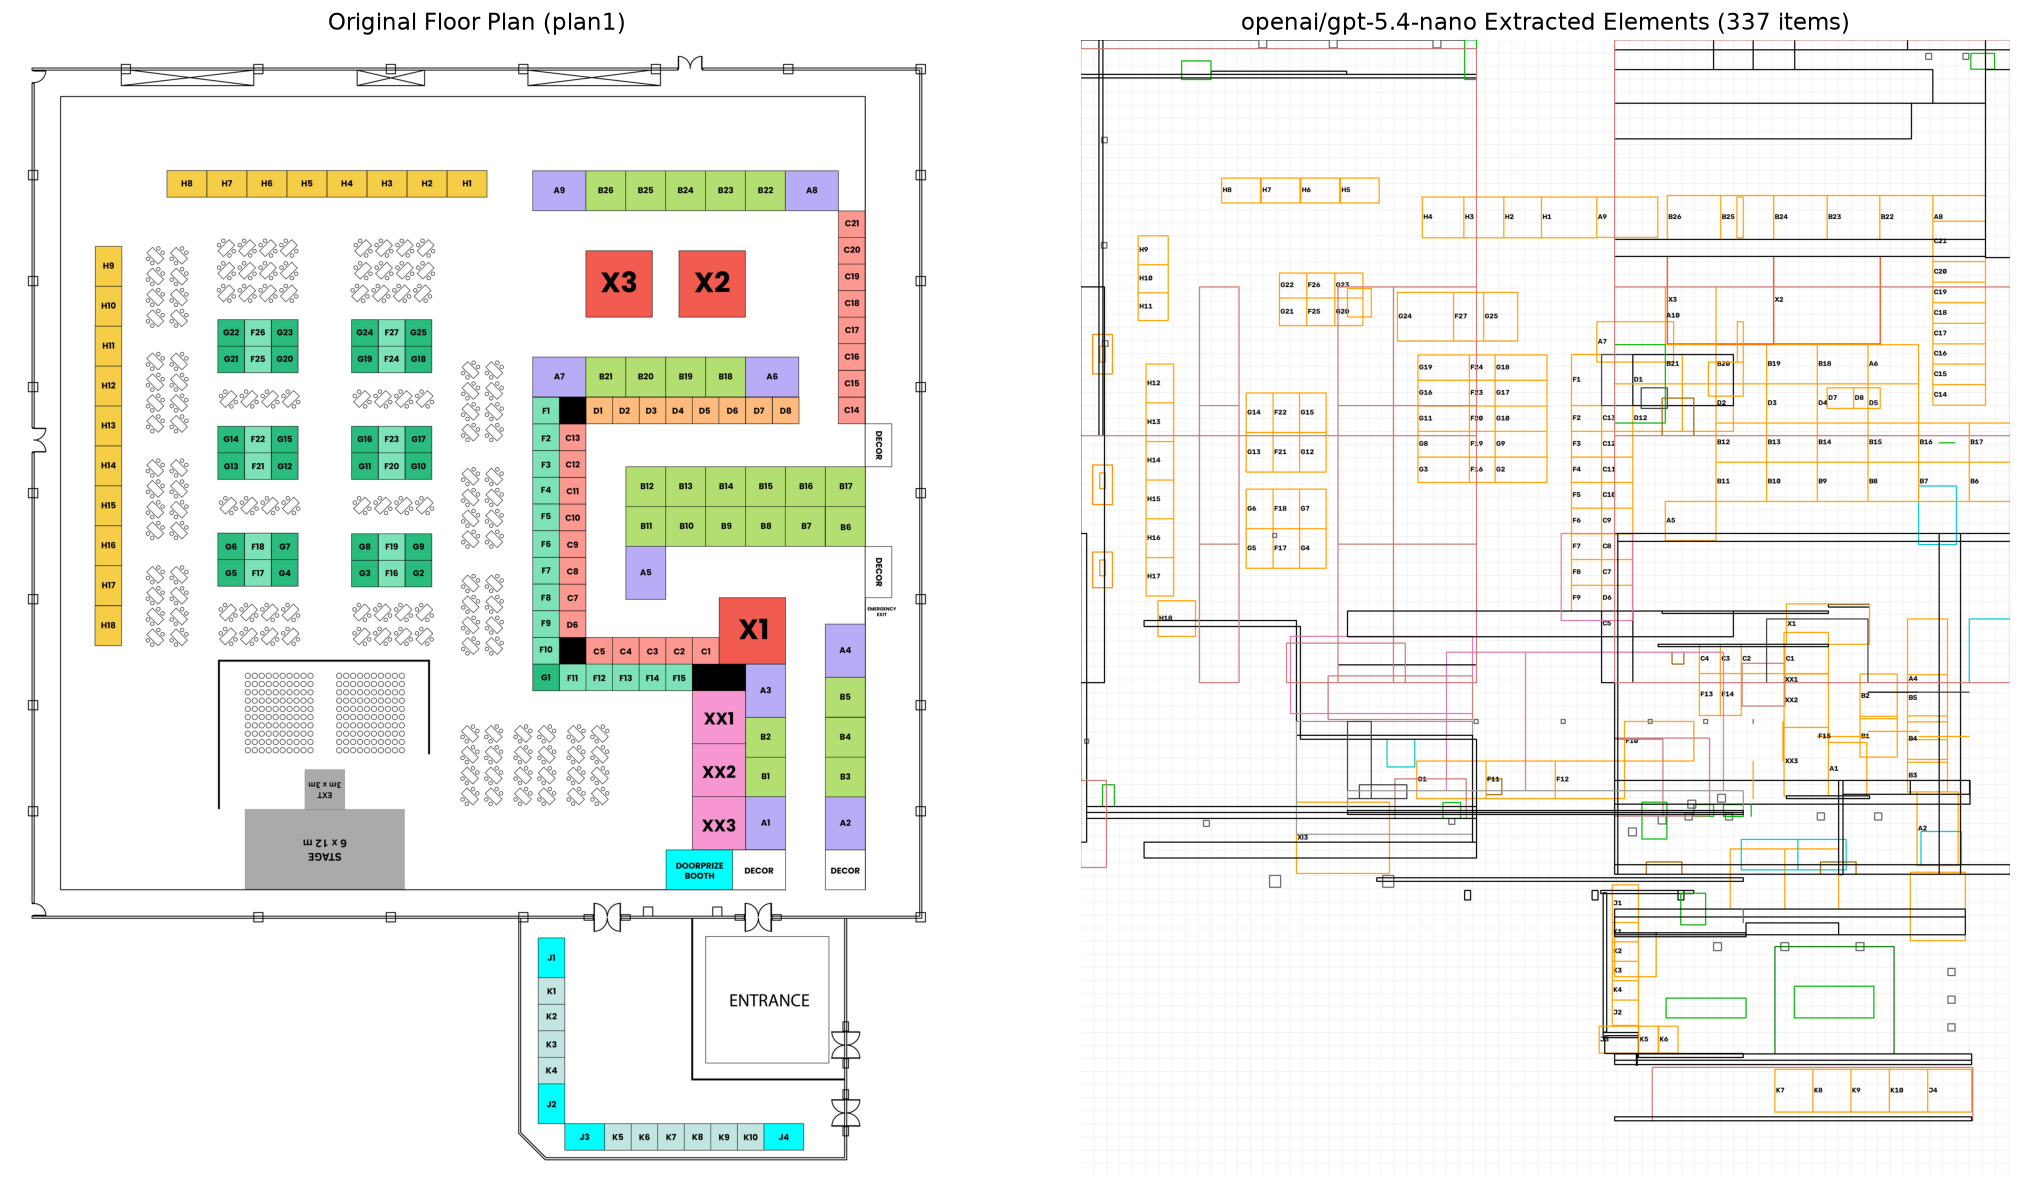

In [35]:
# Side-by-Side Visual Comparison
canvas = np.full((orig_h, orig_w, 3), 255, np.uint8)

step = 60 if "2" in PLAN else 33
for pos in range(0, max(orig_w, orig_h), step):
    cv2.line(canvas, (pos, 0), (pos, orig_h), (230, 230, 230), 1)
    cv2.line(canvas, (0, pos), (orig_w, pos), (230, 230, 230), 1)

coord_mode = result_data.get("coord_mode", "rel1000_xyxy")
colors = {
    "booth": (0, 160, 255),    # orange in BGR
    "large_booth": (0, 60, 255),  # red-orange
    "stage": (150, 150, 150),  # light grey
    "blocked": (60, 60, 60),   # dark grey
    "decor": (200, 200, 0),    # teal
    "stairs": (0, 100, 160),   # brown
    "audience": (180, 120, 220),  # light purple
    "entrance": (0, 120, 0),   # dark green
    "exit": (0, 200, 100),     # green
    "object": (120, 120, 200), # muted red
    "wall": (0, 0, 0),         # black
    "door": (0, 180, 0),       # green
    "pillar": (100, 100, 100), # grey
    "table": (220, 100, 30),   # blue
    "seating": (180, 50, 180), # purple
}

for it in items:
    bb = it.get("box") or it.get("bbox_2d") or it.get("box_2d") or it.get("bbox")
    px_box = convert_box(bb, coord_mode, orig_w, orig_h, orig_w, orig_h)
    x, y, w, h = [int(round(v)) for v in px_box]
    cls = str(it.get("class", "booth")).lower()
    col = colors.get(cls, (0, 140, 255))
    cv2.rectangle(canvas, (x, y), (x + w, y + h), col, 2)
    if it.get("id"):
        cv2.putText(canvas, str(it["id"]), (x + 3, y + h // 2 + 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

active_model_label = MODEL_ID.split('/')[-1] if BACKEND == 'local' else OPENROUTER_MODEL
fig, axes = plt.subplots(1, 2, figsize=(18, 10), dpi=120)
axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original Floor Plan ({PLAN})", fontsize=14)
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"{active_model_label} Extracted Elements ({len(items)} items)", fontsize=14)
axes[1].axis("off")

plt.tight_layout()
plt.show()
